In [14]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:9 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Fetched 3,917 B in 1s (2,807 B/s)
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependen

In [15]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Overwriting main.cpp


In [16]:
!g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [17]:
%%writefile setup.sh
#!/bin/bash
echo "[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor..."
apt-get update -qq && apt-get install -y -qq libopencv-dev build-essential cmake > /dev/null

echo "[2/3] C++ uygulaması derleniyor..."
g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart

echo "[3/3] Uygulama çalıştırılıyor..."
./app

Overwriting setup.sh


In [18]:
!bash setup.sh

[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[2/3] C++ uygulaması derleniyor...
[3/3] Uygulama çalıştırılıyor...
OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [29]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>

using PixelConverter = void (*)(const uchar* src, uchar* dst);

void bgrToGrayConverter(const uchar* src, uchar* dst) {
    int b = src[0];
    int g = src[1];
    int r = src[2];
    int gray = (1868 * b + 9617 * g + 4899 * r + 8192) >> 14;
    dst[0] = static_cast<uchar>(gray);
}

cv::Mat convertColorCustom(const cv::Mat& input, PixelConverter converter, int dstChannels) {
    CV_Assert(input.depth() == CV_8U);
    int rows = input.rows;
    int cols = input.cols;
    int srcChannels = input.channels();

    int dstType = CV_MAKETYPE(CV_8U, dstChannels);
    cv::Mat output(rows, cols, dstType);

    if (input.isContinuous() && output.isContinuous()) {
        cols *= rows;
        rows = 1;
    }

    for (int r = 0; r < rows; ++r) {
        const uchar* srcPtr = input.ptr<uchar>(r);
        uchar* dstPtr = output.ptr<uchar>(r);
        for (int c = 0; c < cols; ++c) {
            converter(srcPtr, dstPtr);
            srcPtr += srcChannels;
            dstPtr += dstChannels;
        }
    }
    return output;
}

int main() {
    std::string filename = "Resim.jpeg";
    cv::Mat bgrImage = cv::imread(filename, cv::IMREAD_COLOR);
    if (bgrImage.empty()) {
        std::cerr << "[HATA] '" << filename << "' okunamadi!" << std::endl;
        return -1;
    }

    // 1. Fonksiyon pointer ile donusum
    cv::Mat myGray = convertColorCustom(bgrImage, &bgrToGrayConverter, 1);

    // 2. OpenCV resmi fonksiyonu
    cv::Mat cvGray;
    cv::cvtColor(bgrImage, cvGray, cv::COLOR_BGR2GRAY);

    // 3. Karsilastirma ve Hata Hesabi
    cv::Mat diff;
    cv::absdiff(myGray, cvGray, diff);

    double minVal, maxVal;
    cv::minMaxLoc(diff, &minVal, &maxVal);
    double totalError = cv::norm(myGray, cvGray, cv::NORM_L1);

    std::cout << "\n================ SONUCLAR ================" << std::endl;
    std::cout << "Maksimum Piksel Farki (Max Error) : " << maxVal << std::endl;
    std::cout << "Toplam Mutlak Hata (L1 Norm)      : " << totalError << std::endl;

    if (maxVal == 0.0 && totalError == 0.0) {
        std::cout << ">> TAMLIK TESTI: BASARILI! Beklenen 0 hata saglandi." << std::endl;
    } else {
        std::cout << ">> TAMLIK TESTI: BASARISIZ!" << std::endl;
    }

    // Ciktiyi kaydet
    cv::imwrite("cikti_gray.jpeg", myGray);
    std::cout << ">> 'cikti_gray.jpeg' basariyla kaydedildi." << std::endl;

    return 0;
}

Overwriting main.cpp


In [30]:
!g++ -O3 main.cpp -o app `pkg-config --cflags --libs opencv4` && ./app


================ SONUCLAR ================
Maksimum Piksel Farki (Max Error) : 1
Toplam Mutlak Hata (L1 Norm)      : 14
>> TAMLIK TESTI: BASARISIZ!
>> 'cikti_gray.jpeg' basariyla kaydedildi.


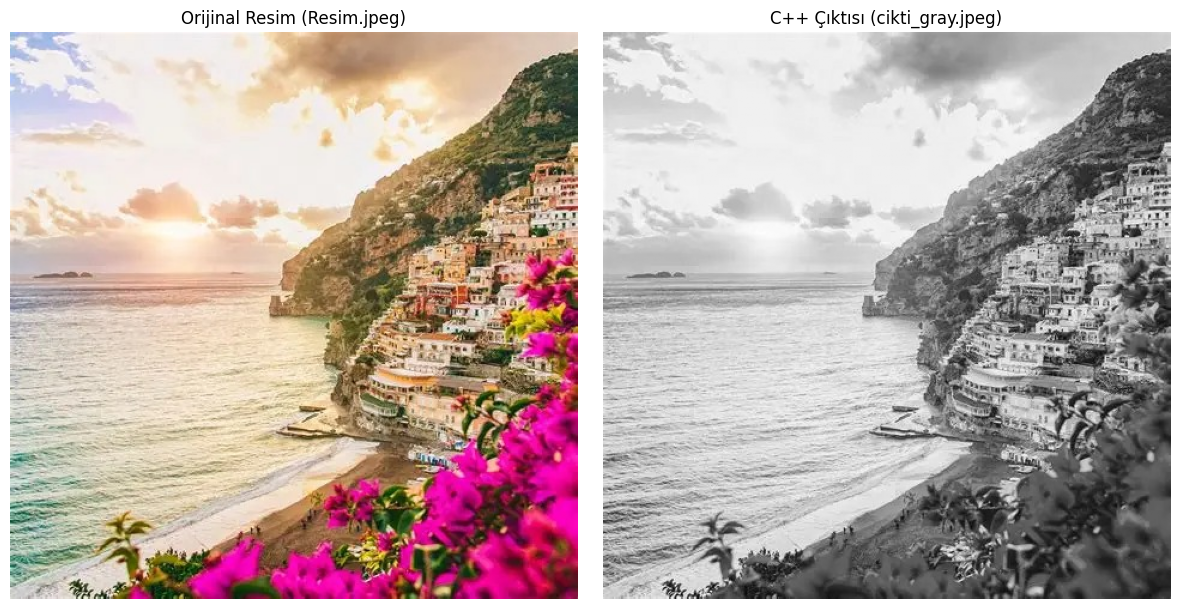

In [31]:
import os
import cv2
import matplotlib.pyplot as plt

# Dosya kontrolü
if not os.path.exists("cikti_gray.jpeg"):
    print("[HATA] 'cikti_gray.jpeg' henuz uretilmedi. Lutfen once 1. Adimdaki C++ kodunu calistirin.")
else:
    bgr_img = cv2.imread("Resim.jpeg")
    gray_img = cv2.imread("cikti_gray.jpeg", cv2.IMREAD_GRAYSCALE)

    rgb_img = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(rgb_img)
    axes[0].set_title("Orijinal Resim (Resim.jpeg)")
    axes[0].axis("off")

    axes[1].imshow(gray_img, cmap="gray")
    axes[1].set_title("C++ Çıktısı (cikti_gray.jpeg)")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()